# 2. Fundamentação teórica

**CatBoost aplicado à previsão de churn**

Atividade Final de Aprendizado de Máquina I · FATEC Jundiaí · Ciência de Dados

| Aluna | Professor | Tema |
|:--|:--|:--|
| Mariana Costa de Mello | Mateus Guilherme Fuini | CatBoost |

## Preparação

A mesma preparação é usada em todos os notebooks:

- `TotalCharges` vem como texto e os 11 valores em branco são de clientes com 0 meses de casa, então viram 0
- `customerID` sai porque é só um identificador
- Divisão estratificada em 60% treino, 20% validação e 20% teste, com semente 42

A primeira célula instala as bibliotecas; o `%%capture` esconde as mensagens da instalação.

In [12]:
%%capture
%pip install catboost shap category_encoders

In [13]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.precision", 3)
SEED = 42

df = pd.read_csv("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].eq("Yes").astype(int)
cats = X.select_dtypes(exclude="number").columns.tolist()

X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.25, stratify=y_trval, random_state=SEED)

## Bagging x boosting

| | Bagging (Random Forest) | Boosting (CatBoost) |
|:--|:--|:--|
| Treino das árvores | Independentes, em paralelo | Em sequência |
| O que cada árvore aprende | O alvo | O erro que sobrou |
| Árvores | Profundas | Rasas |
| Reduz principalmente | Variância | Viés |

## Gradient boosting

O modelo é uma soma de árvores, cada uma dando um passo pequeno na direção que reduz o erro:

$$F_m(x) = F_{m-1}(x) + \eta \, h_m(x)$$

A árvore $h_m$ é treinada no gradiente negativo da perda. Na log-loss isso é só $y_i - p_i$, o alvo menos a probabilidade prevista. $\eta$ é a taxa de aprendizado.

O `GradientBoostingRegressor` do scikit-learn mostra o processo: `staged_predict` devolve a previsão depois de cada árvore.

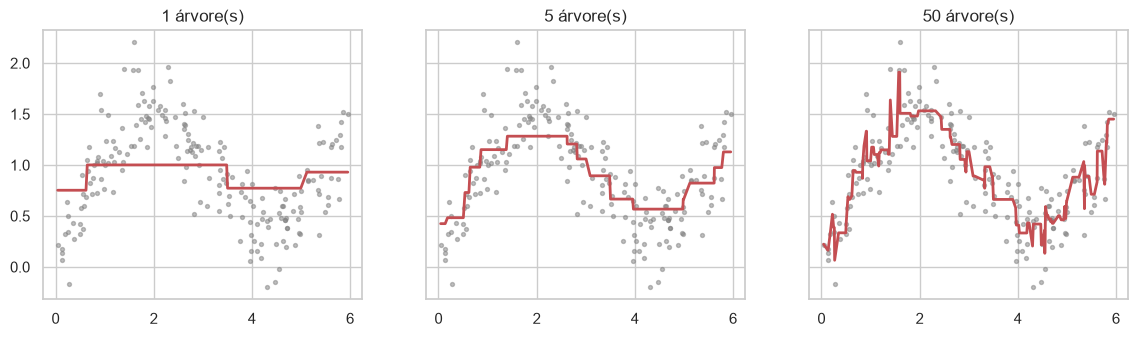

In [14]:
from sklearn.ensemble import GradientBoostingRegressor

rng = np.random.default_rng(SEED)
x = np.sort(rng.uniform(0, 6, 200)).reshape(-1, 1)
alvo = np.sin(x).ravel() + 0.3 * x.ravel() + rng.normal(0, 0.25, 200)
etapas = list(GradientBoostingRegressor(n_estimators=50, learning_rate=0.3, max_depth=2).fit(x, alvo).staged_predict(x))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, m in zip(axes, [1, 5, 50]):
    ax.scatter(x, alvo, s=8, color="gray", alpha=0.5)
    ax.plot(x, etapas[m - 1], color="C3", lw=2)
    ax.set_title(f"{m} árvore(s)")
plt.show()

## Target statistics e vazamento

Uma forma compacta de transformar categoria em número é trocar cada categoria pela **média do alvo** nela, com um valor a priori $p$ de peso $a$:

$$\hat{x}_i = \frac{\sum_j \mathbb{1}[x_j = x_i]\, y_j + a\,p}{\sum_j \mathbb{1}[x_j = x_i] + a}$$

Se a soma inclui a própria linha, o valor carrega o alvo dela. Numa categoria que aparece uma vez só, $\hat{x}_i = (y_i + a\,p)/(1+a)$, uma cópia do alvo. Isso é o **target leakage**.

## Ordered Target Statistics

O CatBoost sorteia uma ordem das linhas e codifica cada uma usando **só as linhas anteriores**. O alvo da própria linha nunca entra na conta.

A biblioteca `category_encoders` tem as duas versões: `TargetEncoder` (simples) e `CatBoostEncoder` (ordenada). No exemplo, `id_unico` não tem informação nenhuma sobre o churn.

In [15]:
from category_encoders import TargetEncoder, CatBoostEncoder

toy = pd.DataFrame({"id_unico": [f"cli_{i}" for i in range(10)], "churn": [1, 0, 1, 0, 0, 1, 0, 1, 0, 1]})
toy["simples"] = TargetEncoder(min_samples_leaf=1, smoothing=1).fit_transform(toy[["id_unico"]], toy["churn"])
toy["ordenado"] = CatBoostEncoder().fit_transform(toy[["id_unico"]], toy["churn"])
display(toy.T)
print("Correlação do simples com o alvo:", round(toy["simples"].corr(toy["churn"]), 2))
print("Valores do ordenado:", toy["ordenado"].unique())

,0,1,2,3,4,5,6,7,8,9
id_unico,cli_0,cli_1,cli_2,cli_3,cli_4,cli_5,cli_6,cli_7,cli_8,cli_9
churn,1,0,1,0,0,1,0,1,0,1
simples,0.75,0.25,0.75,0.25,0.25,0.75,0.25,0.75,0.25,0.75
ordenado,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5


Correlação do simples com o alvo: 1.0
Valores do ordenado: [0.5]


> Na versão simples a coluna vira uma cópia do churn (correlação 1). Na ordenada todos recebem só o valor a priori, que é o correto para uma coluna sem informação.

## Ordered Boosting

A mesma ideia vale para os resíduos: o erro de cada exemplo é calculado por um modelo que **não viu** esse exemplo. Isso evita o *prediction shift*. No CatBoost é o `boosting_type="Ordered"`; o padrão `"Plain"` usa o boosting clássico, mas mantém o Ordered TS nas categóricas.

## Árvores simétricas

Todos os nós de um mesmo nível fazem **a mesma pergunta**. Uma árvore de profundidade $d$ tem $d$ perguntas e $2^d$ folhas. Isso limita o overfitting e deixa a predição muito rápida. As perguntas da primeira árvore de um modelo pequeno:

In [16]:
pool = Pool(X_train, y_train, cat_features=cats)
mini = CatBoostClassifier(iterations=20, depth=3, random_seed=SEED, verbose=0).fit(pool)
pd.DataFrame({"pergunta (igual em todos os nós do nível)": mini._get_tree_splits(0, pool)}).rename_axis("nível")

,pergunta (igual em todos os nós do nível)
nível,
0,"tenure, bin=14.5"
1,"MonthlyCharges, bin=73.95"
2,"tenure, bin=40.5"


## Principais hiperparâmetros

| Parâmetro | O que controla | Efeito |
|:--|:--|:--|
| `iterations` + `early_stopping_rounds` | Número de árvores | Para quando a validação não melhora |
| `learning_rate` | Tamanho do passo | Menor pede mais árvores e generaliza melhor |
| `depth` | Profundidade da árvore | Mais interações, mais risco de overfitting |
| `l2_leaf_reg` | Regularização das folhas | Maior deixa o modelo mais conservador |
| `cat_features` | Colunas categóricas | Ativa o Ordered TS |
| `one_hot_max_size` | Limite para one-hot interno | Acima dele usa TS |
| `boosting_type` | Ordered ou Plain | Ordered combate o prediction shift, é mais lento |
| `auto_class_weights` | Peso das classes | Compensa desbalanceamento |

Valores usados de fato pelo mini-modelo:

In [17]:
pd.Series(mini.get_all_params())[["learning_rate", "depth", "l2_leaf_reg", "boosting_type", "grow_policy", "one_hot_max_size", "border_count"]]

learning_rate                 0.5
depth                           3
l2_leaf_reg                     3
boosting_type               Plain
grow_policy         SymmetricTree
one_hot_max_size                2
border_count                  254
dtype: object